# DecisionLLM: un classificatore a scelta multipla sui logits

Idea: si presenta al modello una domanda con le opzioni `A`, `B`, `C`, `D` e `E) Nessuna delle altre`,
si fa **un solo forward pass** e si legge la distribuzione del token successivo ristretta alle lettere.
Il risultato è un classificatore zero-shot, con una probabilità per ogni classe.

Il notebook segue lo schema di *Robots That Ask For Help* (KnowNo, Ren et al. 2023, [arXiv:2307.01928](https://arxiv.org/abs/2307.01928)):

1. logits e vincolo sulle lettere
2. batch
3. bias posizionale e *scramble* delle risposte
4. conformal prediction per decidere quando il modello è sicuro e quando chiede aiuto
5. calibrazione (ECE, Brier) e decisioni tipizzate (choice, score, sì/no) su uno stato, come un decision model "System 1"

In [1]:
import json, time
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, LogitsProcessor, LogitsProcessorList

MODEL = "LiquidAI/LFM2.5-1.2B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL, padding_side="left")
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16, device_map="cuda").eval()
print(f"{MODEL}: {sum(p.numel() for p in model.parameters())/1e9:.2f}B parametri, "
      f"{torch.cuda.memory_allocated()/2**30:.2f} GB VRAM")

LiquidAI/LFM2.5-1.2B-Instruct: 1.17B parametri, 2.18 GB VRAM


## 1. Il prompt

In [2]:
LETTERS = "ABCDE"
NONE = "Nessuna delle altre"

def build_prompt(question, options, prefix="Risposta:"):
    body = "\n".join(f"{LETTERS[i]}) {o}" for i, o in enumerate(options))
    letters = ", ".join(LETTERS[:len(options) - 1]) + " o " + LETTERS[len(options) - 1]
    instruction = f"Quale opzione è corretta? Rispondi con una sola lettera ({letters}), senza altro testo né formattazione."
    msgs = [{"role": "user", "content": f"{question}\n\n{body}\n\n{instruction}"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False) + prefix

question = "Qual è la capitale dell'Australia?"
options = ["Sydney", "Canberra", "Melbourne", "Perth", NONE]
prompt = build_prompt(question, options)
print(prompt)

<|startoftext|><|im_start|>user
Qual è la capitale dell'Australia?

A) Sydney
B) Canberra
C) Melbourne
D) Perth
E) Nessuna delle altre

Quale opzione è corretta? Rispondi con una sola lettera (A, B, C, D o E), senza altro testo né formattazione.<|im_end|>
<|im_start|>assistant
Risposta:


## 2. I logits del token successivo

`logits_to_keep=1` calcola la testa del vocabolario solo sull'ultima posizione: con vocabolari da
oltre 150k token e batch grandi è la differenza tra pochi MB e decine di GB.

In [3]:
@torch.inference_mode()
def next_token_logits(prompts):
    enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    return model(**enc, logits_to_keep=1, use_cache=False).logits[:, -1, :].float().cpu()

logits = next_token_logits([prompt])[0]
print("shape:", tuple(logits.shape))
top = logits.softmax(-1).topk(10)
for p, i in zip(top.values, top.indices):
    print(f"{tok.decode([i])!r:>12}  {p:.4f}")

shape: (65536,)
        ' B'  1.0000
        ' C'  0.0000
        ' D'  0.0000
         'B'  0.0000
        ' E'  0.0000
        ' A'  0.0000
        '-B'  0.0000
        '{B'  0.0000
       ' BC'  0.0000
        '_B'  0.0000


### Quali token rappresentano una lettera?

Una lettera può esistere come `"B"` e come `" B"` (con spazio). Si prendono entrambe le varianti e si
sommano le probabilità (logsumexp sui logits).

In [4]:
def letter_ids(letter):
    ids = []
    for v in (letter, " " + letter):
        t = tok.encode(v, add_special_tokens=False)
        if len(t) == 1:
            ids.append(t[0])
    return ids

LETTER_IDS = [letter_ids(l) for l in LETTERS]
for l, ids in zip(LETTERS, LETTER_IDS):
    print(l, ids, [tok.decode([i]) for i in ids])

A [542, 835] ['A', ' A']
B [543, 879] ['B', ' B']
C [544, 841] ['C', ' C']
D [545, 889] ['D', ' D']
E [546, 908] ['E', ' E']


## 3. Vincolo sulle lettere: softmax ristretta = logit bias a -inf

Restringere la softmax alle 5 lettere dà esattamente la distribuzione che si otterrebbe generando
un token con tutti gli altri logits a `-inf`. Un logit a `0` invece lascerebbe in gioco tutto il vocabolario,
perché `exp(0) = 1`.

La **massa sulle lettere** (probabilità totale delle lettere nella softmax completa) dice quanto il modello
stava davvero rispondendo con una lettera: se è bassa, la distribuzione rinormalizzata è poco affidabile.

In [5]:
def letter_distribution(logits_row, n=5):
    letter_logits = torch.stack([logits_row[ids].logsumexp(-1) for ids in LETTER_IDS[:n]])
    full = logits_row.log_softmax(-1)
    mass = torch.stack([full[ids].logsumexp(-1) for ids in LETTER_IDS[:n]]).exp().sum()
    return letter_logits.softmax(-1), float(mass)

probs, mass = letter_distribution(logits)
print(f"massa sulle lettere: {mass:.3f}")
for l, o, p in zip(LETTERS, options, probs):
    print(f"{l}) {o:22s} {p:.4f}")
print("argmax:", LETTERS[int(probs.argmax())])

massa sulle lettere: 1.000
A) Sydney                 0.0000
B) Canberra               1.0000
C) Melbourne              0.0000
D) Perth                  0.0000
E) Nessuna delle altre    0.0000
argmax: B


In [6]:
class OnlyLetters(LogitsProcessor):
    def __init__(self, allowed):
        self.allowed = torch.tensor(allowed)
    def __call__(self, input_ids, scores):
        mask = torch.full_like(scores, float("-inf"))
        mask[:, self.allowed.to(scores.device)] = 0
        return scores + mask

enc = tok([prompt], return_tensors="pt", add_special_tokens=False).to(model.device)
out = model.generate(**enc, max_new_tokens=1, do_sample=False, output_scores=True, return_dict_in_generate=True,
                     logits_processor=LogitsProcessorList([OnlyLetters([i for ids in LETTER_IDS for i in ids])]))
print("token generato con il logit bias:", repr(tok.decode(out.sequences[0, -1])))

token generato con il logit bias: ' B'


### Due trappole del prompt

- **Spazio finale**: se il prompt termina con `"Risposta: "` lo spazio è già consumato e il token `" B"` non
  può più uscire. Quanto pesa dipende dal modello: con LFM2.5 la massa sulle lettere scende di poco (cella
  sotto), con altri modelli molto di più: si misura con `bench/run_bench.py prompt`.
- **Formattazione**: con un'istruzione generica alcuni modelli (Qwen3.5) vogliono scrivere `**B**` e il primo
  token è `" **"`. Elencare le lettere ammesse e chiedere "senza altro testo né formattazione" lo risolve.

Entrambe si vedono subito dalla massa sulle lettere.

In [7]:
for prefix in ["", "Risposta:", "Risposta: ", "Risposta: **"]:
    row = next_token_logits([build_prompt(question, options, prefix=prefix)])[0]
    p, m = letter_distribution(row)
    print(f"prefisso {prefix!r:14s} massa lettere {m:.3f}  top libero {tok.decode([int(row.argmax())])!r}")

prefisso ''             massa lettere 1.000  top libero 'B'
prefisso 'Risposta:'    massa lettere 1.000  top libero ' B'
prefisso 'Risposta: '   massa lettere 0.978  top libero ' B'
prefisso 'Risposta: **' massa lettere 1.000  top libero 'B'


## 4. Batch

In [8]:
questions = json.load(open("data/test_questions.json"))
print(len(questions), "domande, esempio:", questions[0])

def score_batch(items, batch_size=64):
    prompts = [build_prompt(q["question"], q["options"] + [NONE]) for q in items]
    out = []
    for i in range(0, len(prompts), batch_size):
        logits = next_token_logits(prompts[i:i + batch_size])
        out += [letter_distribution(row) for row in logits]
    return out

torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.perf_counter()
scored = score_batch(questions)
torch.cuda.synchronize(); dt = time.perf_counter() - t0
acc = sum(LETTERS[int(p.argmax())] == q["answer"] for (p, _), q in zip(scored, questions)) / len(questions)
print(f"{len(questions)} domande in {dt:.2f}s ({len(questions)/dt:.0f}/s), picco VRAM "
      f"{torch.cuda.max_memory_allocated()/2**30:.2f} GB, accuratezza {acc:.3f}")

256 domande, esempio: {'category': 'aritmetica', 'question': 'Quanto fa 9 + 4?', 'options': ['3', '13', '12', '15'], 'answer': 'B'}


256 domande in 4.57s (56/s), picco VRAM 2.59 GB, accuratezza 0.547


## 5. Bias posizionale

I modelli piccoli tendono a preferire certe lettere a prescindere dal contenuto. Mediando la
probabilità per **lettera mostrata** su molte domande si vede il bias.

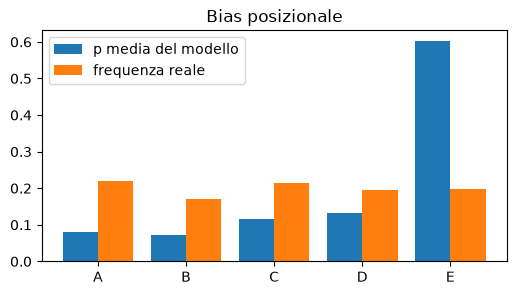

In [9]:
bias = torch.stack([p for p, _ in scored]).mean(0)
truth = torch.tensor([sum(q["answer"] == l for q in questions) / len(questions) for l in LETTERS])
x = range(5)
plt.figure(figsize=(6, 3))
plt.bar([i - .2 for i in x], bias, width=.4, label="p media del modello")
plt.bar([i + .2 for i in x], truth, width=.4, label="frequenza reale")
plt.xticks(list(x), list(LETTERS)); plt.legend(); plt.title("Bias posizionale"); plt.show()

## 6. Scramble answers

La stessa domanda viene posta più volte permutando le opzioni (anche "Nessuna delle altre", come in KnowNo).
Con permutazioni **cicliche** e 5 opzioni, 5 varianti bastano perché ogni risposta occupi ogni lettera
esattamente una volta: il bias posizionale si cancella in media.

Poi si riportano le probabilità all'ordine originale e si aggregano:

- **media aritmetica**: robusta, smussa;
- **media geometrica** (prodotto di esperti, poi rinormalizzato): penalizza un'opzione che anche una sola variante ritiene molto improbabile;
- **media pesata** con peso la massa sulle lettere di ogni variante;
- **voto di maggioranza** sugli argmax.

La **consistenza** è la frazione di varianti il cui argmax coincide con la risposta finale.

In [10]:
def scramble_scores(items, k=5, batch_size=64):
    prompts, meta = [], []
    for qi, q in enumerate(items):
        opts = q["options"] + [NONE]
        n = len(opts)
        for s in range(k):
            order = [(j + s) % n for j in range(n)]
            prompts.append(build_prompt(q["question"], [opts[o] for o in order]))
            meta.append((qi, order))
    per_q = [[] for _ in items]
    for i in range(0, len(prompts), batch_size):
        for row, (qi, order) in zip(next_token_logits(prompts[i:i + batch_size]), meta[i:i + batch_size]):
            p, m = letter_distribution(row, len(order))
            orig = torch.empty_like(p); orig[torch.tensor(order)] = p
            per_q[qi].append((orig, m))
    return [(torch.stack([p for p, _ in v]), torch.tensor([m for _, m in v])) for v in per_q]

def aggregate(v, how, mass=None):
    if how == "mean": return v.mean(0)
    if how == "weighted": return (mass[:, None] * v).sum(0) / mass.sum()
    if how == "geomean": return v.clamp_min(1e-12).log().mean(0).softmax(-1)
    votes = torch.bincount(v.argmax(-1), minlength=v.shape[1]).float()
    return (votes + 1e-3 * v.mean(0)) / (votes + 1e-3 * v.mean(0)).sum()

t0 = time.perf_counter()
variants = scramble_scores(questions)
print(f"{5*len(questions)} prompt in {time.perf_counter()-t0:.2f}s")
answers = [LETTERS.index(q["answer"]) for q in questions]
print(f"senza scramble: {acc:.3f}")
for how in ["mean", "geomean", "weighted", "vote"]:
    a = sum(int(aggregate(v, how, m).argmax()) == y for (v, m), y in zip(variants, answers)) / len(answers)
    print(f"scramble x5 + {how:8s}: {a:.3f}")

1280 prompt in 21.54s
senza scramble: 0.547
scramble x5 + mean    : 0.613
scramble x5 + geomean : 0.633
scramble x5 + weighted: 0.613
scramble x5 + vote    : 0.613


In [11]:
i = next(i for i, (v, _) in enumerate(variants) if (v.argmax(-1) != v.argmax(-1)[0]).any())
q = questions[i]
print(q["question"], q["options"], "| risposta corretta:", q["answer"])
v, m = variants[i]
for k, row in enumerate(v):
    print(f"  variante {k+1}: " + "  ".join(f"{LETTERS[j]}={p:.2f}" for j, p in enumerate(row)) + f"  massa={m[k]:.2f}")
for how in ["mean", "geomean", "weighted", "vote"]:
    f = aggregate(v, how, m)
    print(f"  {how:8s}: " + "  ".join(f"{LETTERS[j]}={p:.2f}" for j, p in enumerate(f)))

Quanto fa 9 + 4? ['3', '13', '12', '15'] | risposta corretta: B
  variante 1: A=0.00  B=0.00  C=0.00  D=0.00  E=1.00  massa=1.00
  variante 2: A=0.10  B=0.04  C=0.05  D=0.16  E=0.65  massa=1.00
  variante 3: A=0.00  B=0.15  C=0.13  D=0.13  E=0.59  massa=1.00
  variante 4: A=0.00  B=0.25  C=0.47  D=0.20  E=0.08  massa=1.00
  variante 5: A=0.00  B=0.33  C=0.55  D=0.12  E=0.00  massa=1.00
  mean    : A=0.02  B=0.15  C=0.24  D=0.12  E=0.46
  geomean : A=0.01  B=0.17  C=0.22  D=0.24  E=0.37
  weighted: A=0.02  B=0.15  C=0.24  D=0.12  E=0.46
  vote    : A=0.00  B=0.00  C=0.40  D=0.00  E=0.60


## 7. Conformal prediction: quando il modello deve chiedere aiuto

Dal paper KnowNo. Su un **set di calibrazione** con risposte note:

1. punteggio di non conformità `κᵢ = 1 - p(risposta corretta)`;
2. `q̂` = quantile empirico di livello `⌈(N+1)(1-ε)⌉ / N` dei `κᵢ`;
3. su una nuova domanda il **prediction set** contiene le opzioni con `p ≥ 1 - q̂`.

Garanzia: la risposta giusta sta nel set con probabilità ≥ `1 - ε`. Se il set contiene una sola opzione il
modello decide, altrimenti chiede aiuto mostrando solo le opzioni plausibili.

In [12]:
import math

final = [aggregate(v, "geomean") for v, _ in variants]
cal_idx, test_idx = range(0, 128), range(128, len(questions))
eps = 0.1
scores = sorted(1 - float(final[i][answers[i]]) for i in cal_idx)
n = len(scores)
qhat = scores[min(n, math.ceil((n + 1) * (1 - eps))) - 1]
print(f"q̂ = {qhat:.3f}  ->  soglia p ≥ {1 - qhat:.3f}")

sets = [[j for j, p in enumerate(final[i]) if p >= 1 - qhat] or [int(final[i].argmax())] for i in test_idx]
coverage = sum(answers[i] in s for i, s in zip(test_idx, sets)) / len(sets)
decided = [(i, s) for i, s in zip(test_idx, sets) if len(s) == 1]
acc_dec = sum(s[0] == answers[i] for i, s in decided) / max(1, len(decided))
print(f"copertura {coverage:.3f} (target ≥ {1-eps})  decise da sole {len(decided)/len(sets):.2%}  "
      f"accuratezza quando decide {acc_dec:.3f}  set medio {sum(map(len, sets))/len(sets):.2f}")

q̂ = 0.954  ->  soglia p ≥ 0.046
copertura 0.922 (target ≥ 0.9)  decise da sole 55.47%  accuratezza quando decide 0.915  set medio 2.05


In [13]:
for eps in [0.02, 0.05, 0.1, 0.2, 0.3]:
    qh = scores[min(n, math.ceil((n + 1) * (1 - eps))) - 1]
    ss = [[j for j, p in enumerate(final[i]) if p >= 1 - qh] or [int(final[i].argmax())] for i in test_idx]
    cov = sum(answers[i] in s for i, s in zip(test_idx, ss)) / len(ss)
    dec = sum(len(s) == 1 for s in ss) / len(ss)
    print(f"ε={eps:.2f}  soglia {1-qh:.3f}  copertura {cov:.3f}  decise {dec:.2%}")

ε=0.02  soglia 0.010  copertura 0.992  decise 45.31%
ε=0.05  soglia 0.032  copertura 0.938  decise 51.56%
ε=0.10  soglia 0.046  copertura 0.922  decise 55.47%
ε=0.20  soglia 0.107  copertura 0.867  decise 60.16%
ε=0.30  soglia 0.204  copertura 0.781  decise 71.88%


## 8. Calibrazione: le probabilità sono affidabili?

Un decision model non deve solo indovinare, deve dare probabilità che significhino qualcosa: tra le risposte
date con confidenza 0.8, circa l'80% dovrebbe essere giusto.

- **ECE** (Expected Calibration Error): si raggruppano le risposte per fascia di confidenza e si media lo scarto
  tra confidenza e accuratezza, pesato per numerosità. 0 = calibrazione perfetta.
- **Brier**: errore quadratico tra il vettore di probabilità e il one-hot della risposta giusta (0 = perfetto, più basso è meglio).
- **Reliability diagram**: accuratezza per fascia di confidenza; un modello calibrato sta sulla diagonale.

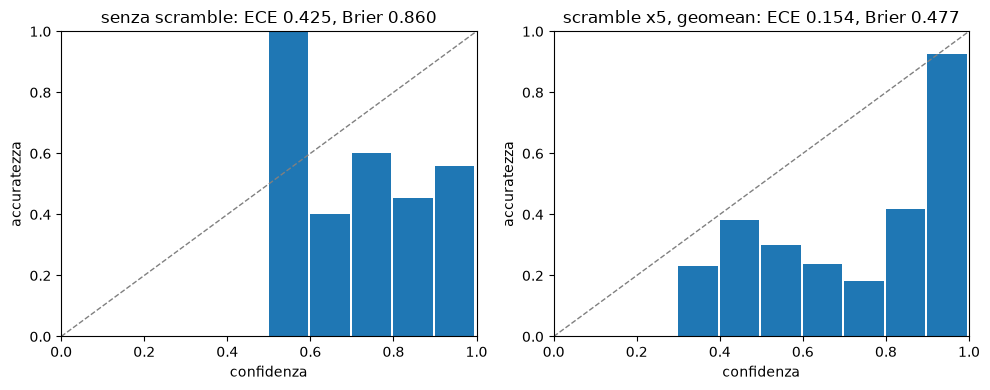

In [14]:
def calibration(probs_list, answers, bins=10):
    conf = torch.tensor([float(p.max()) for p in probs_list])
    hit = torch.tensor([float(int(p.argmax()) == y) for p, y in zip(probs_list, answers)])
    ece, rows = 0.0, []
    for b in range(bins):
        m = (conf > b / bins) & (conf <= (b + 1) / bins)
        if m.any():
            ece += m.float().mean() * (hit[m].mean() - conf[m].mean()).abs()
            rows.append((b / bins, float(conf[m].mean()), float(hit[m].mean()), int(m.sum())))
    brier = sum(float(((p - torch.nn.functional.one_hot(torch.tensor(y), len(p))) ** 2).sum())
                for p, y in zip(probs_list, answers)) / len(answers)
    return float(ece), brier, rows

single = [p for p, _ in scored]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probs_list) in zip(axes, [("senza scramble", single), ("scramble x5, geomean", final)]):
    ece, brier, rows = calibration(probs_list, answers)
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.bar([r[0] for r in rows], [r[2] for r in rows], width=0.095, align="edge")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("confidenza"); ax.set_ylabel("accuratezza")
    ax.set_title(f"{name}: ECE {ece:.3f}, Brier {brier:.3f}")
plt.tight_layout(); plt.show()

## 9. Decisioni tipizzate su uno stato

Lo stesso meccanismo copre i tipi di risposta di un decision model:

- **choice**: scelta tra opzioni (con o senza "Nessuna delle altre");
- **score**: livelli ordinati; il punteggio è la media dei livelli pesata per le probabilità;
- **yesno**: probabilità del sì.

Tutte le domande sono valutate sullo stesso **stato** (un testo di contesto), ognuna con un forward pass. `core.Engine`
fa tutto questo; qui riusa il modello già caricato.

In [15]:
from core import Engine, Question, MODELS_BY_KEY

engine = Engine()
engine.spec, engine.model, engine.tokenizer = MODELS_BY_KEY["lfm2.5-1.2b"], model, tok

state = ("Recensione: Siamo stati al ristorante sabato sera. Il risotto era ottimo e il personale gentile, "
         "ma abbiamo aspettato quasi un'ora per il secondo e il conto era più alto del previsto.")
decisions = [
    Question("Qual è l'aspetto più criticato?", ["Qualità del cibo", "Personale", "Tempi di attesa", "Prezzo"],
             type="choice", none_option=False, state=state, id="critica"),
    Question("Quanto è soddisfatto complessivamente il cliente?", ["Per niente", "Poco", "Abbastanza", "Molto"],
             type="score", state=state, id="soddisfazione"),
    Question("Il cliente cita un problema di prezzo?", type="yesno", state=state, id="prezzo"),
    Question("Il cliente chiede un rimborso?", type="yesno", state=state, id="rimborso"),
]
rep = engine.score(decisions, scramble=1)
for r in rep["results"]:
    if r["type"] == "choice":
        print(f"{r['id']:14s} choice  {r['options'][LETTERS.index(r['argmax'])]!r} (p={r['confidence']:.2f})")
    elif r["type"] == "score":
        print(f"{r['id']:14s} score   {r['score']:.2f} su {len(r['options'])}  " +
              "  ".join(f"{o}={p:.2f}" for o, p in zip(r["options"], r["probs"])))
    else:
        print(f"{r['id']:14s} yesno   p(Sì)={r['p_yes']:.2f}")
print(f"{rep['summary']['prompts']} prompt, forward {1000*rep['summary']['forward_s']:.0f} ms")

critica        choice  'Tempi di attesa' (p=1.00)
soddisfazione  score   3.09 su 4  Per niente=0.00  Poco=0.02  Abbastanza=0.86  Molto=0.12
prezzo         yesno   p(Sì)=0.99
rimborso       yesno   p(Sì)=0.78
4 prompt, forward 119 ms


## Da qui in avanti

- `core.py` contiene la stessa logica in forma riusabile (batching ordinato per lunghezza, gestione OOM, permutazioni, calibrazione).
- `server.py` + `static/index.html` sono la UI interattiva; `/api/decide` espone le decisioni tipizzate come API.
- `bench/run_bench.py` confronta tutti i modelli su Global-MMLU-Lite in italiano.